# Dwa przykłady do dyskusji

## 1. Czy pomiary potwierdzają prawo Ohma?

Idealny opornik ma opór $R = 100\,\Omega$. Napięcie obliczamy ze wzoru $U = RI$, przeliczając prąd z miliamperów na ampery. Każdy odczyt zaburzamy losowo o wartość od −0,1 do +0,1 V.

Opór: 100 Ω
Liczba pomiarów: 21
Średnia różnica pomiar − model: -0.009 V
Odchylenie standardowe różnic: 0.056 V


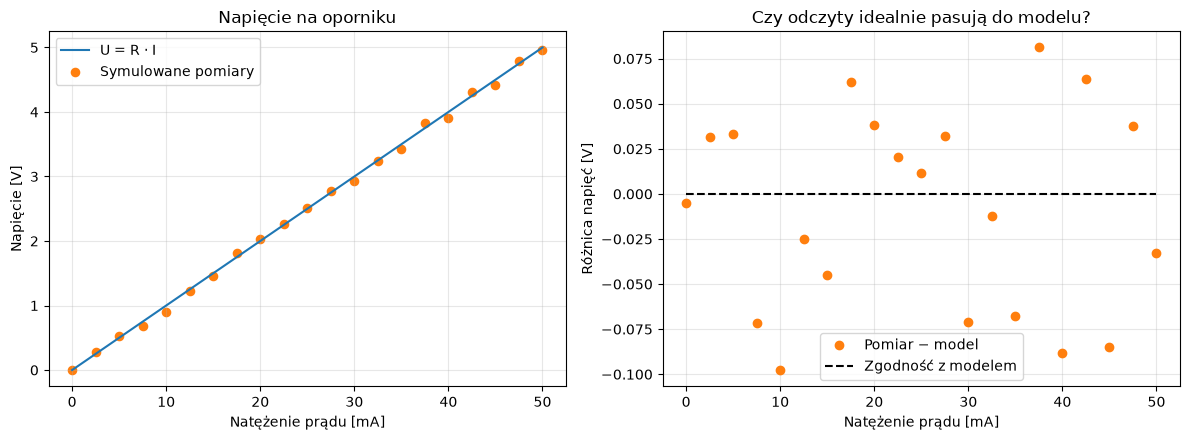

In [1]:
import random
import statistics
import matplotlib.pyplot as plt

def oblicz_napiecie(opor, prad_mA):
    if opor <= 0:
        raise ValueError("Opór musi być dodatni.")
    return opor * prad_mA / 1000

def wykonaj_pomiary(wartosci, zakres_szumu):
    if zakres_szumu < 0:
        raise ValueError("Zakres szumu nie może być ujemny.")
    return [wartosc + random.uniform(-zakres_szumu, zakres_szumu)
            for wartosc in wartosci]

random.seed(12)
opor = 100.0
zakres_szumu = 0.1
prady = [i * 2.5 for i in range(21)]

napiecia_modelu = [oblicz_napiecie(opor, prad) for prad in prady]
napiecia_pomiarow = wykonaj_pomiary(napiecia_modelu, zakres_szumu)
roznice = [pomiar - model
           for pomiar, model in zip(napiecia_pomiarow, napiecia_modelu)]

print(f"Opór: {opor:.0f} Ω")
print(f"Liczba pomiarów: {len(prady)}")
print(f"Średnia różnica pomiar − model: {statistics.mean(roznice):.3f} V")
print(f"Odchylenie standardowe różnic: {statistics.stdev(roznice):.3f} V")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(prady, napiecia_modelu, color="tab:blue", label="U = R · I")
ax1.scatter(prady, napiecia_pomiarow, color="tab:orange",
            s=35, label="Symulowane pomiary")
ax1.set_title("Napięcie na oporniku")
ax1.set_xlabel("Natężenie prądu [mA]")
ax1.set_ylabel("Napięcie [V]")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(prady, roznice, "o", color="tab:orange", label="Pomiar − model")
ax2.plot([prady[0], prady[-1]], [0, 0], "--", color="black",
         label="Zgodność z modelem")
ax2.set_title("Czy odczyty idealnie pasują do modelu?")
ax2.set_xlabel("Natężenie prądu [mA]")
ax2.set_ylabel("Różnica napięć [V]")
ax2.legend()
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 2. Który termometr mierzy lepiej?

Dwa termometry mierzą wodę o stałej temperaturze 37 °C. Termometr A dodaje losową różnicę od −0,2 do +0,2 °C. Termometr B dodaje od −0,05 do +0,05 °C, ale stale zawyża wskazanie o 0,4 °C.

Temperatura odniesienia: 37.0 °C
Termometr A: średnia = 36.984 °C, odchylenie = 0.113 °C
Termometr B: średnia = 37.398 °C, odchylenie = 0.027 °C


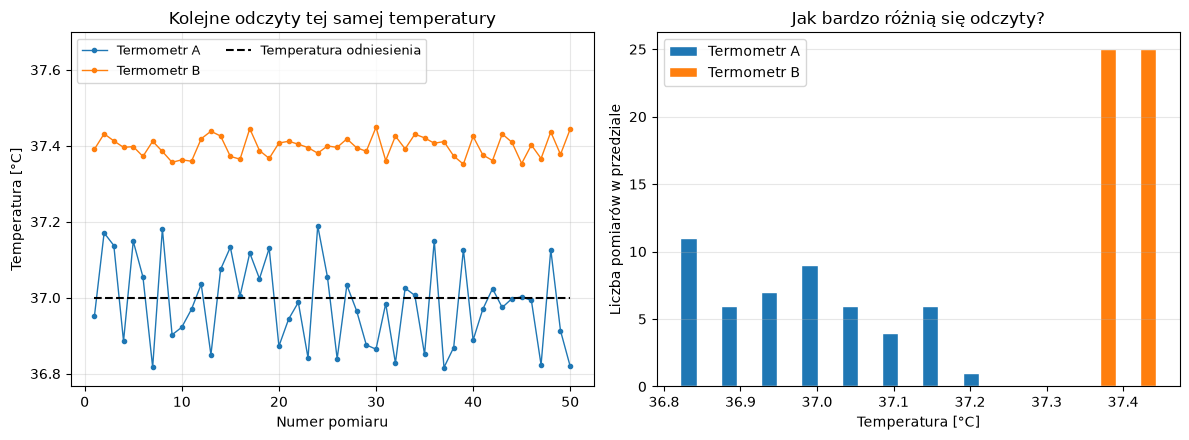

In [5]:
import random
import statistics
import matplotlib.pyplot as plt

def symuluj_termometr(temperatura, przesuniecie, zakres_szumu, liczba):
    if liczba < 2 or zakres_szumu < 0:
        raise ValueError("Potrzeba co najmniej 2 pomiarów i nieujemnego zakresu szumu.")
    return [temperatura + przesuniecie + random.uniform(-zakres_szumu, zakres_szumu)
            for _ in range(liczba)]

def wypisz_statystyki(nazwa, pomiary):
    srednia = statistics.mean(pomiary)
    odchylenie = statistics.stdev(pomiary)
    print(f"{nazwa}: średnia = {srednia:.3f} °C, odchylenie = {odchylenie:.3f} °C")

random.seed(25)
temperatura_wody = 37.0
liczba_pomiarow = 50
szum_a = 0.2
szum_b = 0.05
przesuniecie_b = 0.4

pomiary_a = symuluj_termometr(temperatura_wody, 0, szum_a, liczba_pomiarow)
pomiary_b = symuluj_termometr(temperatura_wody, przesuniecie_b, szum_b, liczba_pomiarow)
numery = list(range(1, liczba_pomiarow + 1))

print(f"Temperatura odniesienia: {temperatura_wody:.1f} °C")
wypisz_statystyki("Termometr A", pomiary_a)
wypisz_statystyki("Termometr B", pomiary_b)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(numery, pomiary_a, "o-", markersize=3, linewidth=1,
         color="tab:blue", label="Termometr A")
ax1.plot(numery, pomiary_b, "o-", markersize=3, linewidth=1,
         color="tab:orange", label="Termometr B")
ax1.plot([1, liczba_pomiarow], [temperatura_wody, temperatura_wody],
         "--", color="black", label="Temperatura odniesienia")
ax1.set_title("Kolejne odczyty tej samej temperatury")
ax1.set_xlabel("Numer pomiaru")
ax1.set_ylabel("Temperatura [°C]")
ax1.set_ylim(min(pomiary_a + pomiary_b) - 0.05,
             max(pomiary_a + pomiary_b) + 0.25)
ax1.legend(loc="upper left", ncol=2, fontsize=9)
ax1.grid(alpha=0.3)

ax2.hist([pomiary_a, pomiary_b], bins=12,
         color=["tab:blue", "tab:orange"],
         label=["Termometr A", "Termometr B"], edgecolor="white")
ax2.set_title("Jak bardzo różnią się odczyty?")
ax2.set_xlabel("Temperatura [°C]")
ax2.set_ylabel("Liczba pomiarów w przedziale")
ax2.legend()
ax2.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## Zadanie

1. Proszę napisać program symulujący po 50 pomiarów napięcia dwoma miernikami. Opór wynosi $220\,\Omega$, a prąd 10 mA. Proszę obliczyć napięcie odniesienia z prawa Ohma. Miernik A dodaje losową różnicę od −0,1 do +0,1 V, a miernik B — od −0,03 do +0,03 V oraz stałe przesunięcie +0,3 V.
2. Proszę obliczyć i wypisać średnią oraz odchylenie standardowe odczytów każdego miernika.
3. Proszę zrobić dwa wykresy: odczyty w kolejności pomiarów z linią napięcia odniesienia oraz histogramy obu serii ze wspólnymi przedziałami. Proszę krótko porównać mierniki.

Można wykorzystać funkcje i fragmenty kodu z obu przykładów.